<a href="https://colab.research.google.com/github/NikhilTheAi/NikhilTheAi-Machine-Learning-Experiments/blob/main/Spam_HamEmailDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPERIMENT 5 - Spam Email Detection

## Step 1 - Import Required Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Step 2 - Load the Dataset

In [5]:
df = pd.read_csv("spam_email.csv")

## Step 3 - Display the Dataset

In [6]:
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Step 4 - Check Dataset Information

In [7]:
print("Shape of dataset:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Shape of dataset: (5572, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
Category    0
Message     0
dtype: int64


## Step 5 - Check Spam and Ham Distribution

In [8]:
print(df["Category"].value_counts())

Category
ham     4825
spam     747
Name: count, dtype: int64


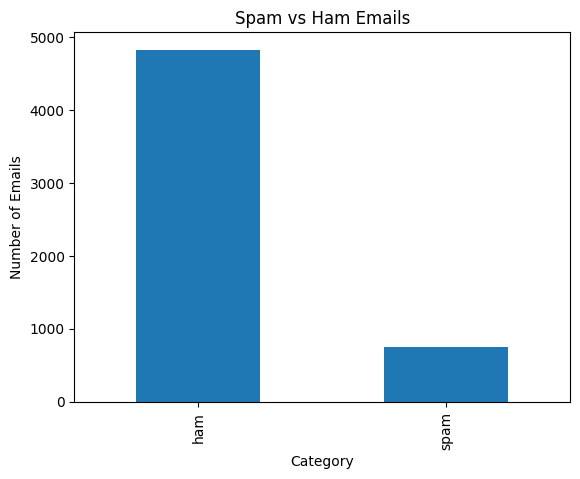

In [9]:
df["Category"].value_counts().plot(kind="bar")

plt.title("Spam vs Ham Emails")
plt.xlabel("Category")
plt.ylabel("Number of Emails")
plt.show()

## Step 6 - Convert Labels into Numbers

In [10]:
df["Category"] = df["Category"].map({
    "ham": 0,
    "spam": 1
})

df.head()

,Category,Message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


## Step 7 - Separate Input and Output

In [11]:
X = df["Message"]
y = df["Category"]

print(X.head())
print(y.head())

0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: Message, dtype: object
0    0
1    0
2    1
3    0
4    0
Name: Category, dtype: int64


## Step 8 - Split Dataset into Training and Testing Data

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4457,)
Testing Data: (1115,)


## Step 9 - Convert Text into Numerical Features Using TF-IDF

In [13]:
tfidf = TfidfVectorizer(
    stop_words="english",
    lowercase=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (4457, 7398)
Testing TF-IDF Shape: (1115, 7398)


## Step 10 - Naive Bayes

In [14]:
nb = MultinomialNB()

nb.fit(X_train_tfidf, y_train)

nb_pred = nb.predict(X_test_tfidf)

nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", nb_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 0.9695067264573991

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       966
           1       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



## Step 11 - Logistic Regression

In [15]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_tfidf, y_train)

lr_pred = lr.predict(X_test_tfidf)

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

Logistic Regression Accuracy: 0.9668161434977578

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       966
           1       1.00      0.75      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



## Step 12 - Support Vector Machine (SVM)

In [16]:
svm = SVC(kernel="linear")

svm.fit(X_train_tfidf, y_train)

svm_pred = svm.predict(X_test_tfidf)

svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", svm_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.9838565022421525

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.99      0.89      0.94       149

    accuracy                           0.98      1115
   macro avg       0.99      0.94      0.96      1115
weighted avg       0.98      0.98      0.98      1115



## Step 13 - Decision Tree

In [17]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train_tfidf, y_train)

dt_pred = dt.predict(X_test_tfidf)

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 0.9632286995515695

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       966
           1       0.87      0.85      0.86       149

    accuracy                           0.96      1115
   macro avg       0.92      0.92      0.92      1115
weighted avg       0.96      0.96      0.96      1115



## Step 14 - Random Forest

In [18]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_tfidf, y_train)

rf_pred = rf.predict(X_test_tfidf)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.9739910313901345

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       966
           1       1.00      0.81      0.89       149

    accuracy                           0.97      1115
   macro avg       0.99      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115



## Step 15 - Compare All Algorithms

In [19]:
results = pd.DataFrame({
    "Algorithm": [
        "Naive Bayes",
        "Logistic Regression",
        "SVM",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy,
        dt_accuracy,
        rf_accuracy
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

print(results)

             Algorithm  Accuracy  Accuracy (%)
2                  SVM  0.983857     98.385650
4        Random Forest  0.973991     97.399103
0          Naive Bayes  0.969507     96.950673
1  Logistic Regression  0.966816     96.681614
3        Decision Tree  0.963229     96.322870


## Step 16 - Plot Algorithm Comparison

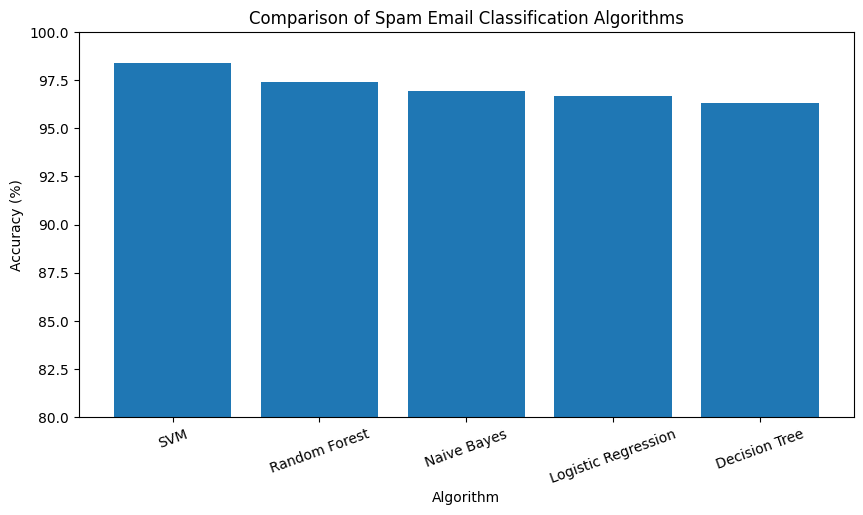

In [20]:
plt.figure(figsize=(10, 5))

plt.bar(
    results["Algorithm"],
    results["Accuracy (%)"]
)

plt.title("Comparison of Spam Email Classification Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=20)
plt.ylim(80, 100)

plt.show()

## Step 17 - Find the Best Performing Algorithm

In [21]:
best_model = results.iloc[0]

print("Best Algorithm:", best_model["Algorithm"])
print("Best Accuracy:", round(best_model["Accuracy (%)"], 2), "%")

Best Algorithm: SVM
Best Accuracy: 98.39 %


## Step 18 - Confusion Matrix

In [22]:
cm = confusion_matrix(y_test, svm_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[965   1]
 [ 17 132]]


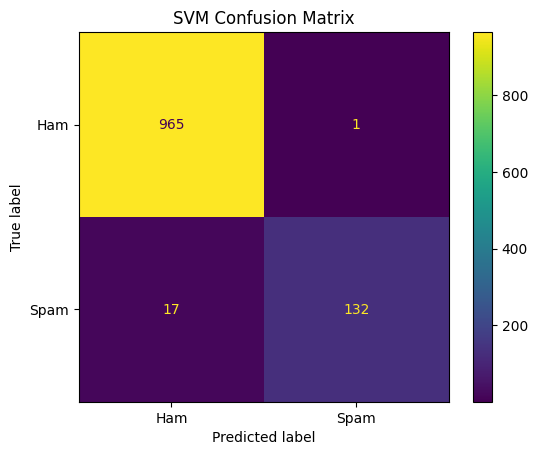

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
).plot()

plt.title("SVM Confusion Matrix")
plt.show()

## Step 19 - Test the Model with a New Email

In [24]:
email = ["Congratulations! You have won a free prize. Click here to claim now."]

email_tfidf = tfidf.transform(email)

prediction = svm.predict(email_tfidf)

if prediction[0] == 1:
    print("Spam Email")
else:
    print("Ham Email")

Spam Email


In [25]:
email = ["Hi, are you coming to college tomorrow?"]

email_tfidf = tfidf.transform(email)

prediction = svm.predict(email_tfidf)

if prediction[0] == 1:
    print("Spam Email")
else:
    print("Ham Email")

Ham Email


## Step 20 - Conclusion

## Conclusion

- Successfully built a Spam Email Detection system.
- Used TF-IDF to convert email text into numerical features.
- Compared Naive Bayes, Logistic Regression, SVM, Decision Tree, and Random Forest.
- The best-performing model was identified based on accuracy.
- The model can classify new emails as Spam or Ham.